---
title: "Chapter 19: Time series"
---

::: {.callout-lo}
## Learning outcomes {.unnumbered}

By the end of this chapter, you should be able to:

- Define a forecasting task in terms of prediction time, available information, and forecast horizon.
- Use chronological holdouts and temporal cross-validation to evaluate forecasts.
- Construct calendar and lag features and choose representations suited to a model.
- Distinguish repeated one-step forecasting from recursive and direct multi-step forecasting.
- Explain seasonality, trends, and the limits of extrapolation.
:::

**Imports**

In [1]:
#| code-fold: true
#| code-summary: "Show imports and setup"
from pathlib import Path

import matplotlib.pyplot as plt
import mglearn
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures

DATA_DIR = Path("data") if Path("data").is_dir() else Path("book") / "data"
plt.rcParams["font.size"] = 12

## From supervised learning to forecasting

Suppose you manage a bicycle rental station in New York City. You want to predict how many rentals will occur during a future three-hour period so you can plan where bikes will be needed. Rental demand helps with planning, although predicting how many bikes will remain also requires information about returns and the station's current inventory.

You already know several regression models. What would you use as features, and how would you evaluate the predictions?

We will use the Citi Bike example from *Introduction to Machine Learning with Python*, available through `mglearn`. Each timestamp marks the beginning of a three-hour rental-count interval.

starttime
2015-08-01 00:00:00     3
2015-08-01 03:00:00     0
2015-08-01 06:00:00     9
2015-08-01 09:00:00    41
2015-08-01 12:00:00    39
Freq: 3h, Name: rentals, dtype: int64

2015-08-01 00:00:00 to 2015-08-31 21:00:00


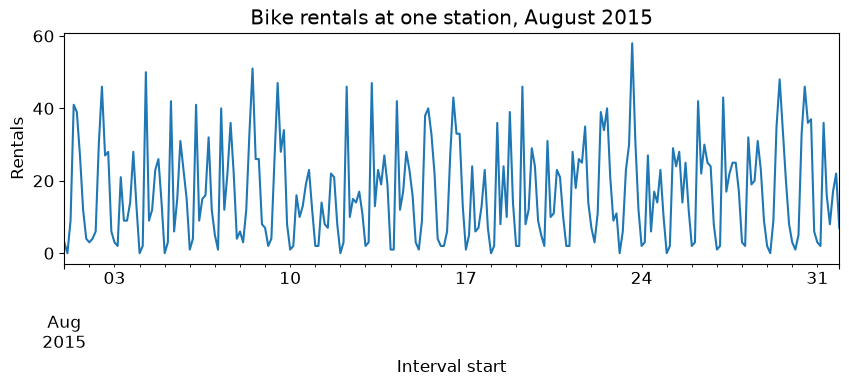

In [2]:
rentals = mglearn.datasets.load_citibike().rename("rentals")
display(rentals.head())
print(f"{rentals.index.min()} to {rentals.index.max()}")
ax = rentals.plot(figsize=(10, 3), ylabel="Rentals", xlabel="Interval start")
ax.set_title("Bike rentals at one station, August 2015")
plt.show()

What patterns do you notice? Demand changes with the time of day, and weekdays differ from weekends. These recurring patterns are examples of **seasonality**. Here, seasonality can be daily or weekly; it need not refer to seasons of the year.

A **time series** records observations in time order. Nearby observations often carry information about one another: a busy rental period may follow another busy period. This temporal dependence is useful information, but our familiar regressors do not use row order automatically. We must give them suitable features.

For our main task, we make a prediction at the beginning of each three-hour interval, using rental counts from completed intervals and calendar information for the interval ahead. We assume completed counts are available immediately. The **forecast horizon** describes how far ahead we predict. If counts arrive with a delay, our features must respect that delay too.

This is a **univariate** series: we observe one variable, rental count, over time. Recording weather as well would give us multiple variables. Recording rentals at many stations would give us multiple related series. A hierarchy adds aggregation relationships, such as station totals adding up to city totals. These distinctions matter when constructing lags and evaluating models.

We will adapt the supervised learning tools we already know. Specialized time-series models are another option, but they are outside this chapter's scope.

## Evaluating forecasts

How would you split this dataset? Our usual random split puts earlier and later observations in both sets. Let's inspect what that means.

In [3]:
random_train, random_test = train_test_split(rentals, test_size=0.2, random_state=123)
print("Latest training interval:", random_train.index.max())
print("Earliest test interval:", random_test.index.min())

Latest training interval: 2015-08-31 21:00:00
Earliest test interval: 2015-08-01 12:00:00


Some training observations occur after test observations. This does not reproduce learning from the past to forecast the future. For this forecasting task, we instead hold out the last eight days and train on the first 23 days.

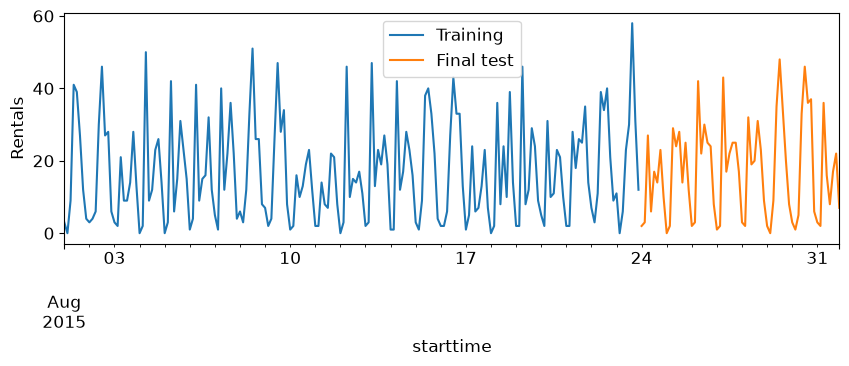

In [4]:
n_train = 184
train = rentals.iloc[:n_train]
test = rentals.iloc[n_train:]
ax = train.plot(figsize=(10, 3), label="Training", ylabel="Rentals")
test.plot(ax=ax, label="Final test")
ax.legend()
plt.show()

### Validation that moves forward in time

We still need to compare features and models without repeatedly consulting the final test set. `TimeSeriesSplit` constructs folds in which training observations precede validation observations. Its default training window expands as more observations become available. For this regularly spaced series, row counts also correspond to elapsed time.

In [5]:
cv = TimeSeriesSplit(n_splits=3, test_size=32)
for fold, (fit_rows, valid_rows) in enumerate(cv.split(train), start=1):
    print(f"Fold {fold}: train {fit_rows[0]}–{fit_rows[-1]}, "
          f"validate {valid_rows[0]}–{valid_rows[-1]}")

Fold 1: train 0–87, validate 88–119
Fold 2: train 0–119, validate 120–151
Fold 3: train 0–151, validate 152–183


We will compare models using **mean absolute error (MAE)**, measured in rentals per interval. Lower is better. Before fitting a model, establish simple reference forecasts. A **persistence** forecast repeats the last observed count. A **seasonal naive** forecast repeats the count from the same interval one day earlier.

Our validation setup predicts one interval at a time. Observed counts become available between predictions, although the fitted model stays fixed during each validation fold. Therefore a later validation row may use an earlier validation count as a lag. That would be unavailable if we forecast the entire validation period at its beginning.

In [6]:
baseline_predictions = pd.DataFrame({
    "Previous interval": rentals.shift(1),
    "Same interval yesterday": rentals.shift(8),
})
baseline_scores = {}
for name in baseline_predictions:
    errors = []
    for _, valid_rows in cv.split(train):
        errors.append(mean_absolute_error(
            train.iloc[valid_rows], baseline_predictions[name].iloc[valid_rows]
        ))
    baseline_scores[name] = np.mean(errors)
display(pd.Series(baseline_scores, name="Validation MAE"))

Previous interval          13.041667
Same interval yesterday     7.677083
Name: Validation MAE, dtype: float64

::: {.callout-note}
### Think it through

A model uses yesterday's rentals to predict today's rentals. Is it valid to use observed rentals from the validation period?

It depends on the prediction task. They are available for later predictions if observations arrive each day. They are unavailable when forecasting the whole period in advance. A chronological split alone does not settle this question.
:::

## Engineering temporal features

### Start with a numeric timestamp

A timestamp is not yet a useful numerical representation for every model. One possibility is elapsed seconds since the Unix epoch, often called POSIX time. Will a random forest learn the repeating rental pattern from this single increasing number? Predict the shape of its validation predictions before running the example.

Each comparison below plots observed and predicted rentals on the same last validation fold. The plot shows the final week of its training window and the following four validation days, with identical axes across models. All earlier training rows are still used for fitting. Training predictions show what the model can fit; validation predictions show which patterns carry forward. The printed cross-validation MAE averages over all three folds. The final test period remains untouched.

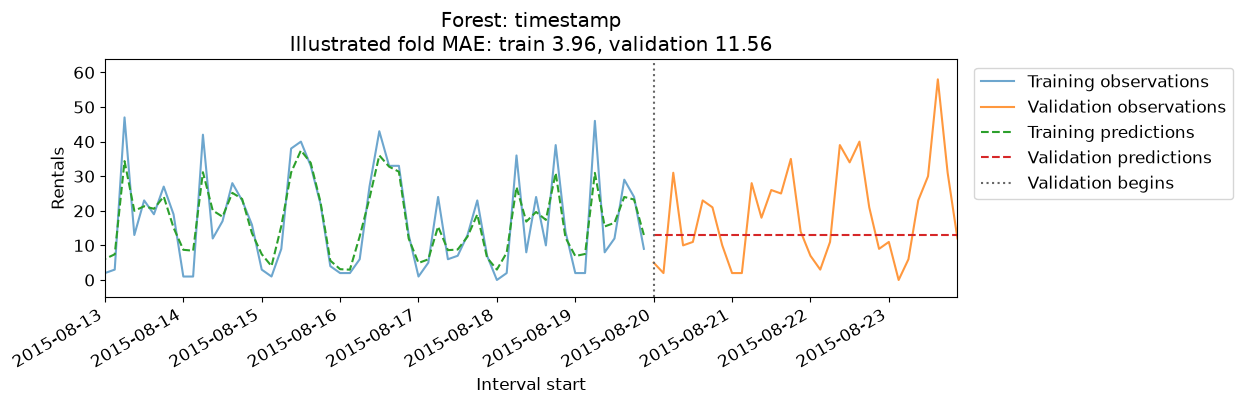

Mean cross-validation MAE: 11.40 rentals


In [7]:
# Explicitly request seconds; do not assume the datetime storage resolution.
calendar = pd.DataFrame({
    "elapsed_seconds": rentals.index.as_unit("s").asi8,
    "hour": rentals.index.hour,
    "weekday": rentals.index.dayofweek,
}, index=rentals.index)
y_train = train.to_numpy()
validation_results = {}

# Use the same last validation fold for every illustration.
# Cross-validation scores still average over all three folds.
plot_fit_rows, plot_valid_rows = list(cv.split(train))[-1]

def compare(name, model, features):
    scores = -cross_val_score(
        model, features.iloc[:n_train], y_train,
        cv=cv, scoring="neg_mean_absolute_error",
    )
    validation_results[name] = scores.mean()
    fitted = clone(model).fit(features.iloc[plot_fit_rows], train.iloc[plot_fit_rows])
    fit_predictions = fitted.predict(features.iloc[plot_fit_rows])
    valid_predictions = fitted.predict(features.iloc[plot_valid_rows])
    fit_mae = mean_absolute_error(train.iloc[plot_fit_rows], fit_predictions)
    valid_mae = mean_absolute_error(train.iloc[plot_valid_rows], valid_predictions)

    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(train.index[plot_fit_rows], train.iloc[plot_fit_rows],
            color="C0", label="Training observations", alpha=0.65)
    ax.plot(train.index[plot_valid_rows], train.iloc[plot_valid_rows],
            color="C1", label="Validation observations", alpha=0.8)
    ax.plot(train.index[plot_fit_rows], fit_predictions, "--",
            color="C2", label="Training predictions")
    ax.plot(train.index[plot_valid_rows], valid_predictions, "--",
            color="C3", label="Validation predictions")
    boundary = train.index[plot_valid_rows[0]]
    ax.axvline(boundary, color="0.4", linestyle=":", label="Validation begins")
    # Zoom to the last training week and all four validation days.
    ax.set_xlim(boundary - pd.Timedelta(days=7), train.index[plot_valid_rows[-1]])
    ax.set_ylim(-5, train.max() * 1.1)
    ax.set(xlabel="Interval start", ylabel="Rentals", title=(
        f"{name}\nIllustrated fold MAE: train {fit_mae:.2f}, validation {valid_mae:.2f}"
    ))
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.autofmt_xdate()
    plt.show()
    print(f"Mean cross-validation MAE: {scores.mean():.2f} rentals")
    return fitted

forest = RandomForestRegressor(n_estimators=100, random_state=123)
timestamp_model = compare("Forest: timestamp", forest, calendar[["elapsed_seconds"]])

All validation timestamps are later than the training timestamps. A regression tree sends these values into the same outermost leaf, whose prediction is an average of training targets. Averaging across trees still gives a constant prediction here.

A standard regression forest cannot extend an increasing or decreasing relationship beyond its learned partitions. It can accept new feature values, but it does not extrapolate a trend from this timestamp. We need features that expose the recurring patterns instead.

### Calendar features and model choice

The plot suggests that hour and weekday matter. These features recur in future intervals, so a forest can reuse patterns learned from earlier days.

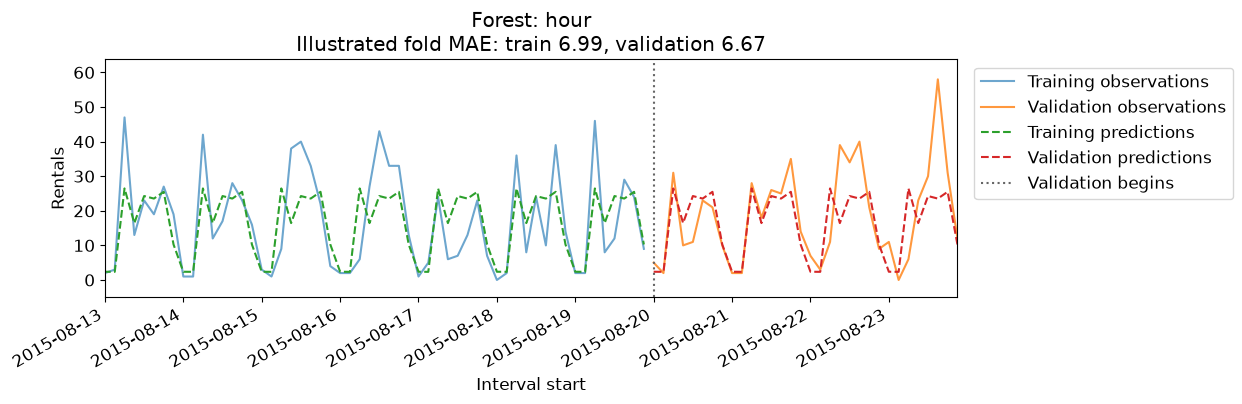

Mean cross-validation MAE: 6.97 rentals


In [8]:
hour_model = compare("Forest: hour", forest, calendar[["hour"]])

The hour-only model repeats the same daily profile. It can describe busy and quiet hours, but must use that same pattern on weekdays and weekends. Look at the training predictions: the missing day-to-day variation is a limitation of the representation, not simply a failure to generalize.

What additional calendar information could let the model distinguish a weekend afternoon from a weekday afternoon? Let's add the day of the week.

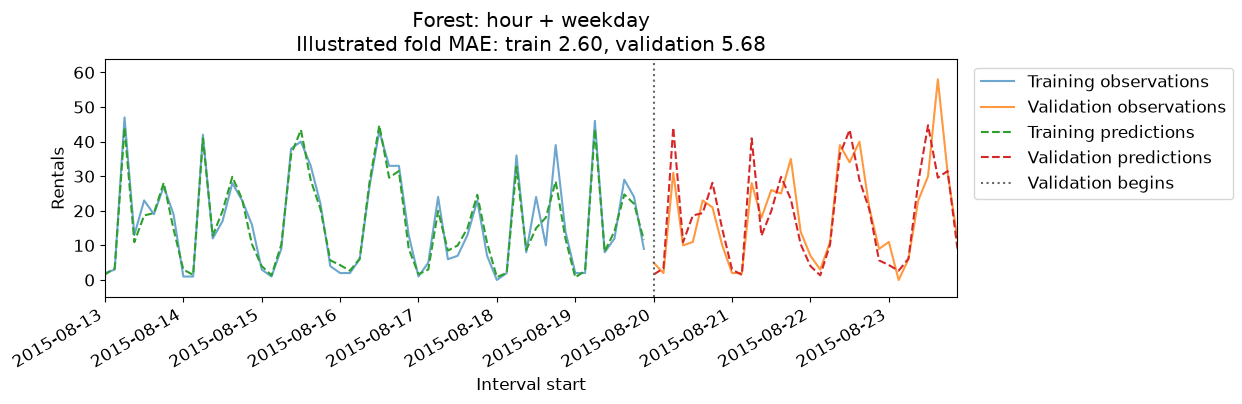

Mean cross-validation MAE: 4.36 rentals


In [9]:
calendar_features = calendar[["hour", "weekday"]]
calendar_forest_model = compare("Forest: hour + weekday", forest, calendar_features)

Now the forest can use both hour and weekday in its splits. Compare the shapes of the daily peaks with the previous plot, and check the validation error rather than assuming that every added feature helps.

Do we need a forest to use these two features? Let's try Ridge with exactly the same numeric inputs. Before running it, consider what one coefficient for hour and one for weekday allow the model to express.

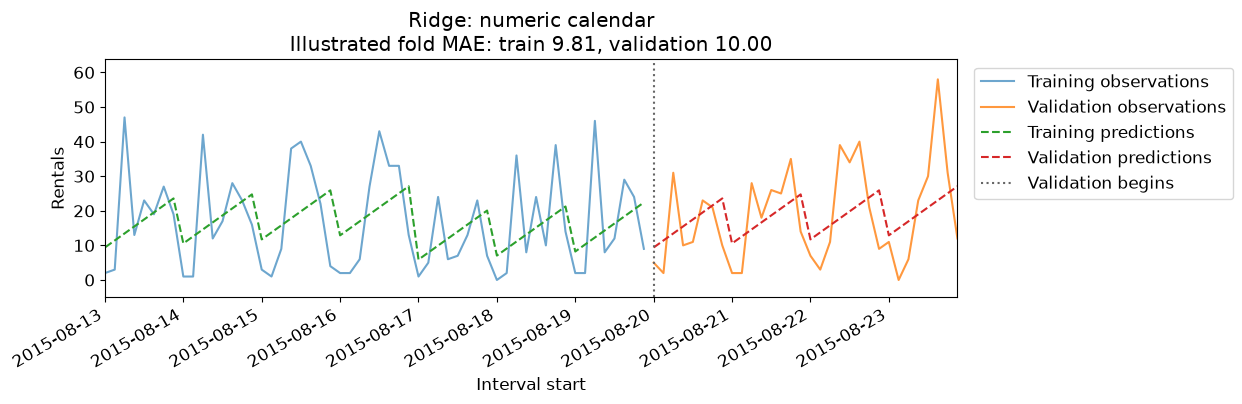

Mean cross-validation MAE: 10.00 rentals


In [10]:
numeric_ridge_model = compare("Ridge: numeric calendar", Ridge(), calendar_features)

Why might Ridge struggle even on the training data? Numeric hour gives it one coefficient: each additional hour changes the prediction by the same amount. That cannot describe morning and evening peaks. Numeric weekday imposes a similarly restrictive relationship.

One-hot encoding gives each hour and weekday its own effect. It does not explicitly tell the model that 21:00 and 00:00 are close in time. It does allow a separate prediction contribution for each observed hour.

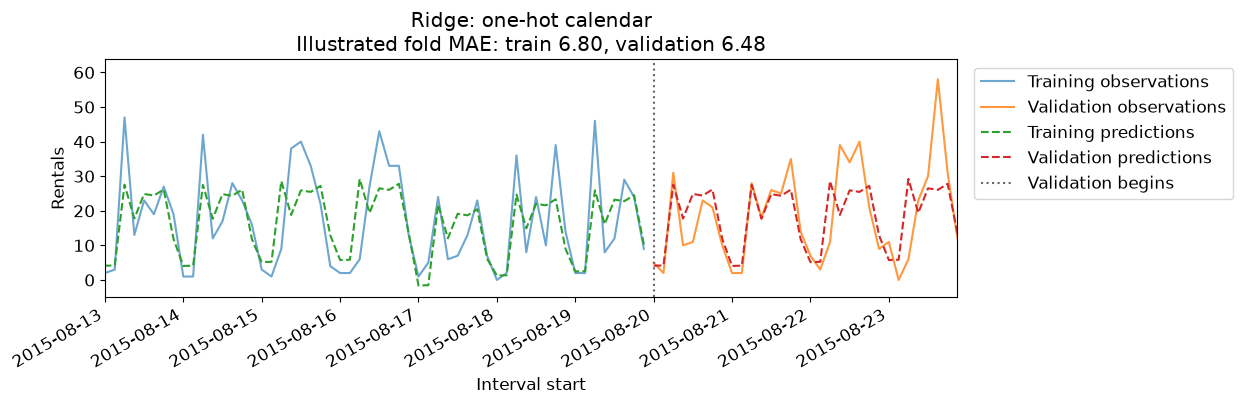

Mean cross-validation MAE: 6.93 rentals


In [11]:
calendar_ridge = make_pipeline(
    OneHotEncoder(handle_unknown="ignore", sparse_output=False), Ridge()
)
onehot_model = compare("Ridge: one-hot calendar", calendar_ridge, calendar_features)

Inspect the encoded rows alongside the prediction plot. Each row activates one hour category and one weekday category. Unlike a numeric hour coefficient, the model can assign unrelated effects to 06:00, 09:00, and 12:00.

In [12]:
encoder = onehot_model.named_steps["onehotencoder"]
encoded_calendar = pd.DataFrame(
    encoder.transform(calendar_features.iloc[plot_fit_rows]),
    columns=encoder.get_feature_names_out(),
    index=train.index[plot_fit_rows],
)
display(encoded_calendar.head(8))

,hour_0,hour_3,hour_6,hour_9,hour_12,hour_15,hour_18,hour_21,weekday_0,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6
starttime,,,,,,,,,,,,,,,
2015-08-01 00:00:00,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2015-08-01 03:00:00,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2015-08-01 06:00:00,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2015-08-01 09:00:00,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2015-08-01 12:00:00,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2015-08-01 15:00:00,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2015-08-01 18:00:00,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2015-08-01 21:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


This model still adds the same hourly effect on every weekday. What if the morning commute peak occurs on weekdays but not weekends? **Interaction features** let the effect of one feature depend on another. A weekday–hour interaction can represent a particular combination, such as Monday at 09:00.

The pipeline below fits encoding separately inside each training fold. `PolynomialFeatures` creates pairwise products; products between mutually exclusive categories are always zero, while hour–weekday products encode combinations.

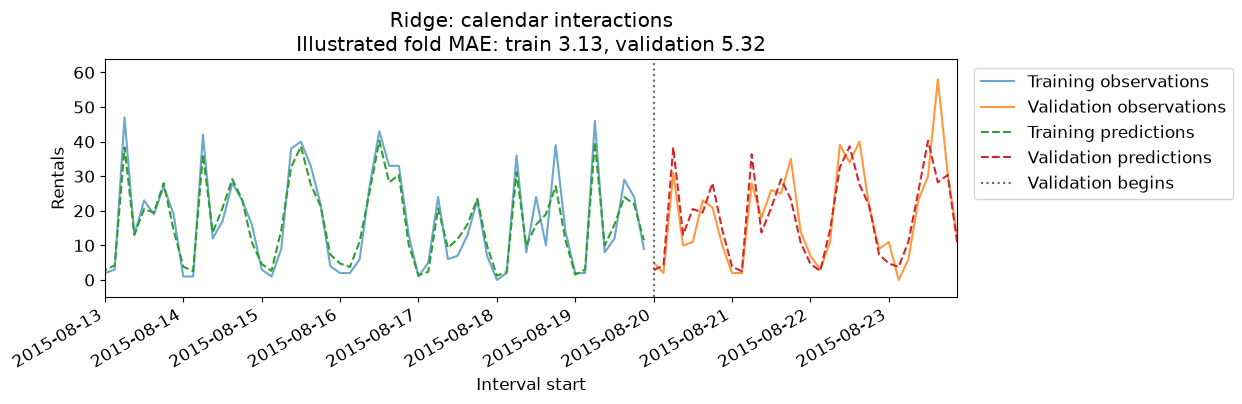

Mean cross-validation MAE: 4.79 rentals


In [13]:
interaction_ridge = make_pipeline(
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
    Ridge(),
)
interaction_model = compare("Ridge: calendar interactions", interaction_ridge, calendar_features)

Compare the one-hot model's daily profiles with those from the interaction model. Without interactions, moving from a weekday to a weekend adds the same weekday effect at every hour. With interactions, the hourly profile itself can change.

We can inspect the corresponding feature products. The displayed interaction columns are active only when both the weekday and hour match.

In [14]:
poly = interaction_model.named_steps["polynomialfeatures"]
interaction_encoder = interaction_model.named_steps["onehotencoder"]
encoded = interaction_encoder.transform(calendar_features.iloc[plot_fit_rows])
interaction_names = poly.get_feature_names_out(interaction_encoder.get_feature_names_out())
interaction_table = pd.DataFrame(
    poly.transform(encoded), columns=interaction_names,
    index=train.index[plot_fit_rows],
)
example_columns = ["hour_9", "weekday_0", "hour_9 weekday_0",
                   "hour_12", "weekday_6", "hour_12 weekday_6"]
display(interaction_table[example_columns].head(16))
coefficients = pd.Series(
    interaction_model.named_steps["ridge"].coef_, index=interaction_names,
    name="Coefficient",
)
interaction_coefficients = coefficients[coefficients.index.str.contains(" ")]
strongest = interaction_coefficients.abs().nlargest(10).index
display(interaction_coefficients.loc[strongest].to_frame())

,hour_9,weekday_0,hour_9 weekday_0,hour_12,weekday_6,hour_12 weekday_6
starttime,,,,,,
2015-08-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0
2015-08-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0
2015-08-01 06:00:00,0.0,0.0,0.0,0.0,0.0,0.0
2015-08-01 09:00:00,1.0,0.0,0.0,0.0,0.0,0.0
2015-08-01 12:00:00,0.0,0.0,0.0,1.0,0.0,0.0
2015-08-01 15:00:00,0.0,0.0,0.0,0.0,0.0,0.0
2015-08-01 18:00:00,0.0,0.0,0.0,0.0,0.0,0.0
2015-08-01 21:00:00,0.0,0.0,0.0,0.0,0.0,0.0
2015-08-02 00:00:00,0.0,0.0,0.0,0.0,1.0,0.0


,Coefficient
hour_6 weekday_6,-17.378082
hour_12 weekday_6,15.241781
hour_9 weekday_5,14.338772
hour_6 weekday_2,14.318346
hour_12 weekday_5,14.143566
hour_6 weekday_5,-13.476297
hour_6 weekday_3,11.306393
hour_6 weekday_4,9.341480
hour_9 weekday_6,6.686986
hour_6 weekday_1,6.621918


A positive interaction coefficient contributes an upward adjustment for that combination; a negative one contributes a downward adjustment. The prediction also includes the intercept, main effects, and other active terms. Because some encoded features overlap and Ridge distributes their weights, an individual coefficient is not the total effect of that time period and should not be read as a causal explanation.

The comparison illustrates why model and representation must be chosen together. Forests can learn interactions through their splits. A linear model needs us to provide the corresponding features.

### Learning from recent observations

Calendar features describe the usual pattern. What information are they missing about an unusually busy or quiet day? Recent rental counts may help. A **lag feature** supplies a past observation as an input for the current prediction.

In [15]:
def add_lags(frame, column, lags):
    """Add past values; rows must be sorted and regularly spaced."""
    return frame.assign(**{
        f"{column}_lag{lag}": frame[column].shift(lag) for lag in lags
    })

lagged = add_lags(rentals.to_frame(), "rentals", [1, 2, 3, 4, 5, 8])
display(lagged.head(10))
lag_features = lagged.drop(columns="rentals")

,rentals,rentals_lag1,rentals_lag2,rentals_lag3,rentals_lag4,rentals_lag5,rentals_lag8
starttime,,,,,,,
2015-08-01 00:00:00,3,NaN,NaN,NaN,NaN,NaN,NaN
2015-08-01 03:00:00,0,3.0,NaN,NaN,NaN,NaN,NaN
2015-08-01 06:00:00,9,0.0,3.0,NaN,NaN,NaN,NaN
2015-08-01 09:00:00,41,9.0,0.0,3.0,NaN,NaN,NaN
2015-08-01 12:00:00,39,41.0,9.0,0.0,3.0,NaN,NaN
2015-08-01 15:00:00,27,39.0,41.0,9.0,0.0,3.0,NaN
2015-08-01 18:00:00,12,27.0,39.0,41.0,9.0,0.0,NaN
2015-08-01 21:00:00,4,12.0,27.0,39.0,41.0,9.0,NaN
2015-08-02 00:00:00,3,4.0,12.0,27.0,39.0,41.0,3.0


`shift(1)` brings the previous row's count into the current row. Here that means three hours earlier; `shift(8)` means one day earlier. The initial rows have missing lag values because our dataset contains no earlier observations. We use an imputer fitted only on each training fold. Dropping the initial incomplete rows is another reasonable option.

This interpretation assumes regular spacing. With missing timestamps, a previous row may be several intervals old. Check the spacing and, if necessary, align to a regular time grid before constructing interval-based lags. Filling missing timestamps creates missing observations; it does not make their values known.

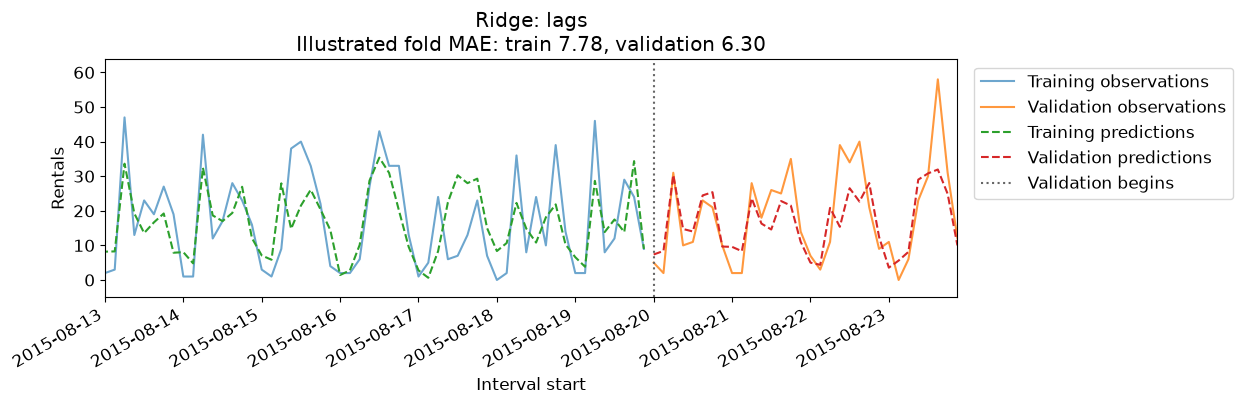

Mean cross-validation MAE: 7.75 rentals


In [16]:
lag_ridge_model = compare("Ridge: lags", make_pipeline(SimpleImputer(), Ridge()), lag_features)

Lag features describe the recent history rather than the position in the week. Inspect whether the linear model follows the peaks and troughs, and whether the validation pattern resembles its training fit. Its coefficients combine several recent counts, which may themselves be strongly related.

Would a nonlinear relationship between recent counts and the next count help? Keep the features unchanged and try a forest.

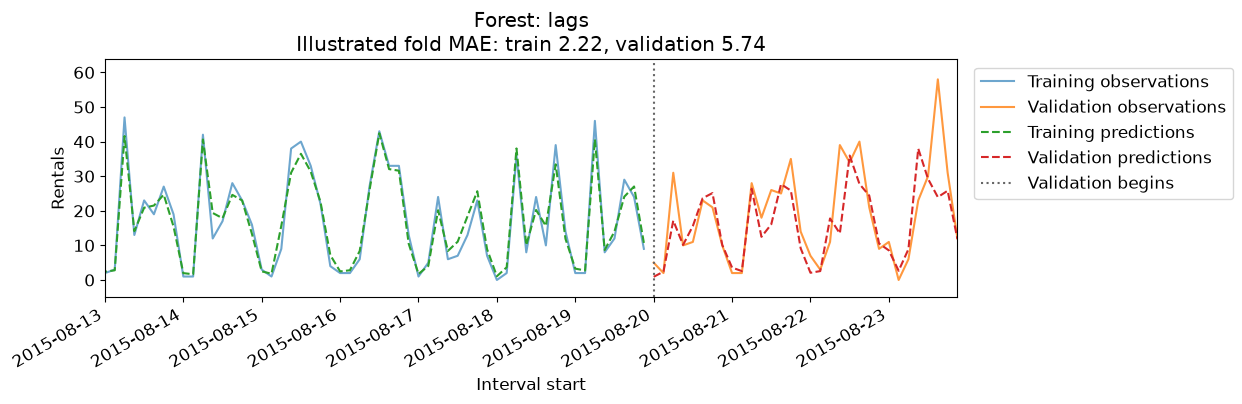

Mean cross-validation MAE: 6.05 rentals


In [17]:
lag_forest_model = compare("Forest: lags", make_pipeline(SimpleImputer(), forest), lag_features)

Compare both lag-only models with the calendar models. A model using recent counts may follow local changes while missing a recurring peak that is easier to anticipate from the clock.

### Combining calendar and recent history

These two feature sets describe different information: when an interval occurs and what happened recently. Can their combination capture what either misses alone? First, keep the calendar interactions for Ridge and add the lag features.

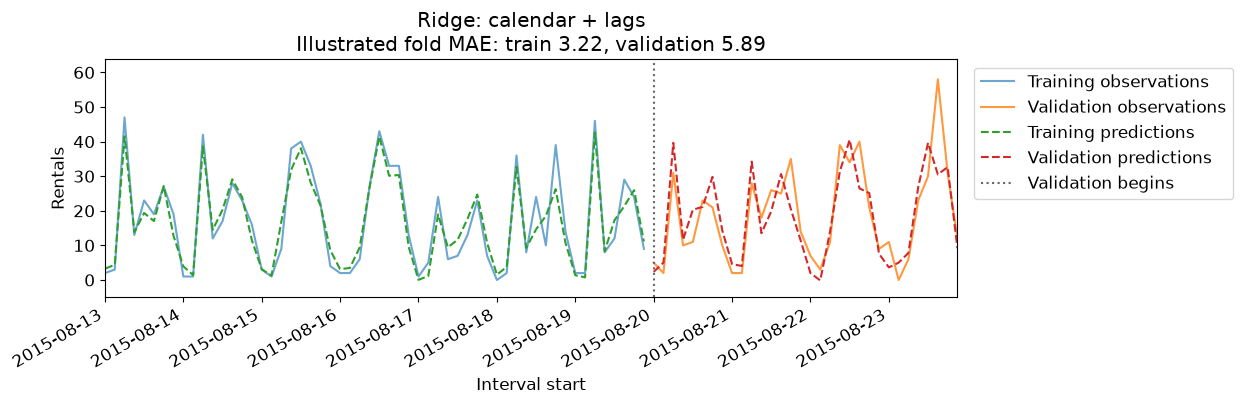

Mean cross-validation MAE: 5.09 rentals


In [18]:
combined = pd.concat([calendar_features, lag_features], axis=1)
lag_columns = lag_features.columns.tolist()
combined_preprocessor = ColumnTransformer([
    ("calendar", make_pipeline(
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        PolynomialFeatures(interaction_only=True, include_bias=False),
    ), ["hour", "weekday"]),
    ("lags", SimpleImputer(), lag_columns),
])
combined_ridge = make_pipeline(combined_preprocessor, Ridge())
combined_model = compare("Ridge: calendar + lags", combined_ridge, combined)

Finally, combine numeric calendar features and lags for the forest. The forest can learn calendar interactions through its splits, so we do not need to supply the one-hot interaction expansion used for Ridge. Compare its training fit and validation predictions: a tighter training fit alone is not evidence of improvement.

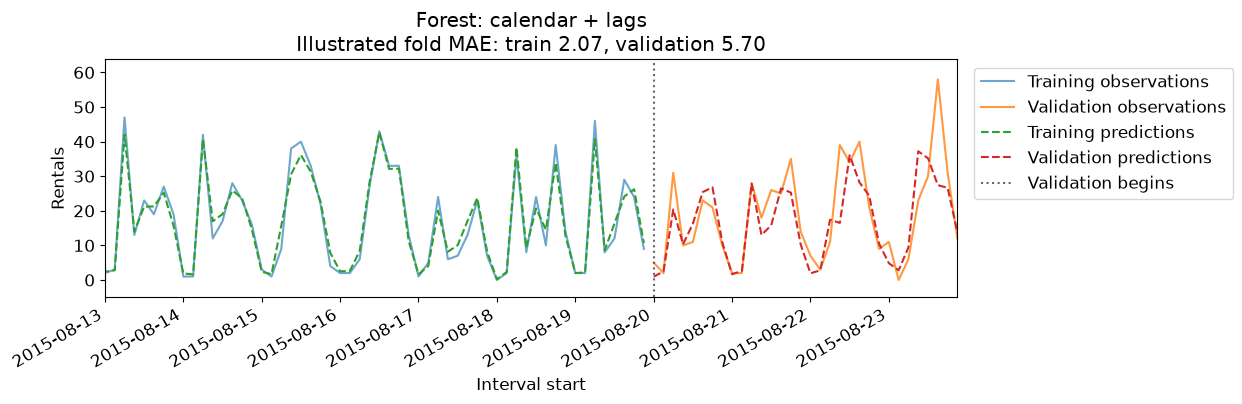

Mean cross-validation MAE: 5.56 rentals


Forest: hour + weekday           4.363437
Ridge: calendar interactions     4.792812
Ridge: calendar + lags           5.086453
Forest: calendar + lags          5.558854
Forest: lags                     6.048437
Ridge: one-hot calendar          6.930686
Forest: hour                     6.974753
Ridge: lags                      7.752851
Ridge: numeric calendar         10.002101
Forest: timestamp               11.396250
Name: Mean validation MAE, dtype: float64

In [19]:
combined_forest = make_pipeline(SimpleImputer(), forest)
combined_forest_model = compare("Forest: calendar + lags", combined_forest, combined)
display(pd.Series(validation_results, name="Mean validation MAE").sort_values())

Compare these errors with the simple baselines. More features do not guarantee better forecasts. Five recent intervals may contain little information beyond the calendar pattern, while a daily lag offers a different kind of history. The appropriate lag lengths depend on the sampling interval and the patterns we expect.

### One final test

We now select among the candidates using validation MAE. This small dataset makes those comparisons uncertain, so small differences should not be treated as decisive. The test below evaluates the selected procedure once, under the same repeated one-step prediction setup.

Selected: Forest: hour + weekday
Final test MAE: 3.53 rentals


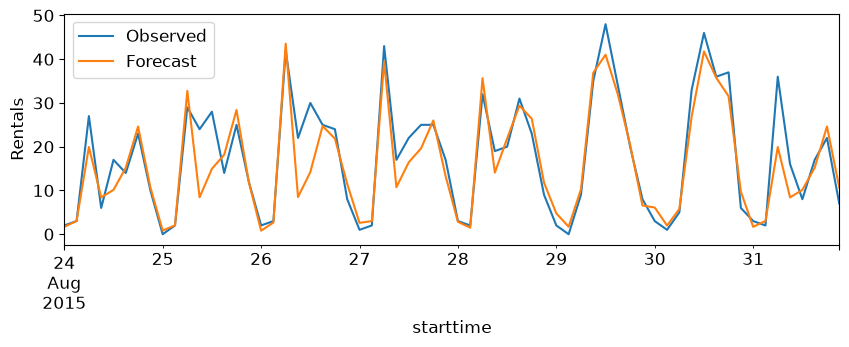

In [20]:
candidates = {
    "Forest: timestamp": (forest, calendar[["elapsed_seconds"]]),
    "Forest: hour": (forest, calendar[["hour"]]),
    "Forest: hour + weekday": (forest, calendar_features),
    "Ridge: numeric calendar": (Ridge(), calendar_features),
    "Ridge: one-hot calendar": (calendar_ridge, calendar_features),
    "Ridge: calendar interactions": (interaction_ridge, calendar_features),
    "Ridge: lags": (make_pipeline(SimpleImputer(), Ridge()), lag_features),
    "Forest: lags": (make_pipeline(SimpleImputer(), forest), lag_features),
    "Ridge: calendar + lags": (combined_ridge, combined),
    "Forest: calendar + lags": (combined_forest, combined),
}
best_name = min(validation_results, key=validation_results.get)
selected_model, selected_features = candidates[best_name]
fitted_model = clone(selected_model).fit(selected_features.iloc[:n_train], train)
test_predictions = fitted_model.predict(selected_features.iloc[n_train:])
print("Selected:", best_name)
print(f"Final test MAE: {mean_absolute_error(test, test_predictions):.2f} rentals")
ax = test.plot(figsize=(10, 3), label="Observed", ylabel="Rentals")
pd.Series(test_predictions, index=test.index).plot(ax=ax, label="Forecast")
ax.legend()
plt.show()

## Forecasting multiple steps ahead

Imagine standing at the beginning of a three-hour interval and requesting predictions for the next five intervals. Can we use all the lag rows we constructed above?

No. For the first forecast we know the preceding counts. For the second, the most recent count belongs to an interval that has not finished yet. Our earlier evaluation allowed observations to arrive between predictions; this request does not.

### Recursive forecasting

One option is to fit a one-step model and repeatedly feed its predictions back as lag inputs. This is **recursive**, or iterative, forecasting. The example below uses the first five lags. It fits on complete training rows and forecasts five intervals from one fixed origin. It does not read any test rental counts.

In [21]:
recursive_columns = [f"rentals_lag{i}" for i in range(1, 6)]
complete = lagged.iloc[:n_train].dropna(subset=recursive_columns)
one_step_model = clone(forest).fit(complete[recursive_columns], complete["rentals"])
history = train.tolist()
recursive_predictions = []
for _ in range(5):
    next_features = pd.DataFrame(
        [[history[-i] for i in range(1, 6)]], columns=recursive_columns
    )
    prediction = one_step_model.predict(next_features)[0]
    recursive_predictions.append(prediction)
    history.append(prediction)
display(pd.DataFrame({"Recursive forecast": recursive_predictions}, index=test.index[:5]))

,Recursive forecast
starttime,
2015-08-24 00:00:00,6.11
2015-08-24 03:00:00,4.76
2015-08-24 06:00:00,13.45
2015-08-24 09:00:00,18.81
2015-08-24 12:00:00,19.40


This reuses one model, but later inputs contain earlier prediction errors. Errors can propagate, and training on observed lags differs from predicting with estimated lags. Performance should be checked separately at each horizon using historical forecast origins.

### Direct forecasting

Alternatively, train a separate model for each horizon. At origin $t$, every model uses information already available at $t$, but one predicts the interval starting at $t$, another the interval starting three hours later, and so on. Construct each horizon's target by shifting the outcome forward relative to the origin's features. Exclude training examples whose target interval crosses the training cutoff.

Direct forecasting avoids feeding predictions back into inputs, but requires more models and leaves fewer complete training examples at longer horizons. Future calendar features are known in advance; future observed weather or rental counts are not. Weather forecasts could be inputs if equivalent forecasts were available when training and evaluating.

A third option is a multi-output model that predicts several horizons at once. Some such models share information across outputs; others fit outputs independently. We will not develop these models here.

::: {.callout-note}
### Check your understanding

You forecast all of next week's demand on Sunday evening. A validation feature for Thursday contains Wednesday's observed demand. What is wrong?

Wednesday's demand was unknown at the forecast origin. Use a prediction in a recursive approach, or construct a direct model using only information available on Sunday. Merely placing Thursday after the training dates does not prevent this leakage.
:::

## Seasonality, trends, and extrapolation

Calendar features capture recurring patterns, but what if the overall level changes over several years? A **trend** is a sustained upward or downward movement over time. It is different from seasonality: December peaks can recur while the level of sales also rises.

The monthly retail-sales series below comes from the Federal Reserve Bank of St. Louis. We use it to examine these two patterns, rather than repeat the full forecasting workflow.

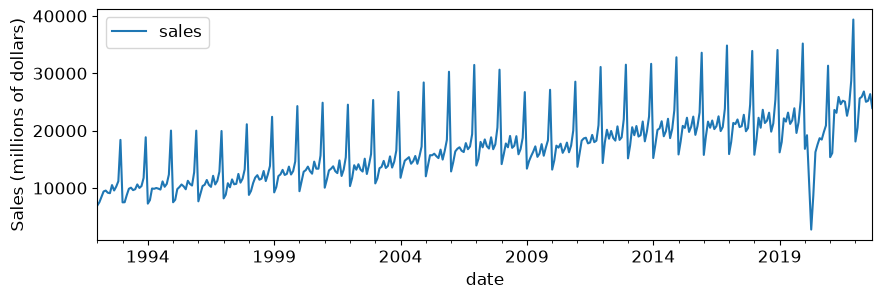

,date,sales,days_since_start
0,1992-01-01,6938,0
1,1992-02-01,7524,31
2,1992-03-01,8475,60
3,1992-04-01,9401,91
4,1992-05-01,9558,121


In [22]:
retail = pd.read_csv(DATA_DIR / "MRTSSM448USN.csv", parse_dates=["DATE"])
retail.columns = ["date", "sales"]
retail.plot(x="date", y="sales", figsize=(10, 3), ylabel="Sales (millions of dollars)")
plt.show()
retail_train = retail.loc[retail["date"] <= pd.Timestamp("2016-01-01")].copy()
first_date = retail_train["date"].min()
retail_train["days_since_start"] = (retail_train["date"] - first_date).dt.days
display(retail_train.head())

An elapsed-time feature gives a linear model a way to represent a trend. A positive coefficient extends growth at a constant rate, including beyond the training period. That is an assumption, not a guarantee about future sales. Real trends can change, flatten, or reverse.

A standard random forest does not extend that slope. With elapsed time as its only feature, later timestamps reach outermost leaves. With calendar and lag features too, its predictions can vary, but it still does not extrapolate a growing trend in the way a linear model can. Regression-forest predictions are averages of training targets and remain within their observed range.

One possible approach is to estimate a trend and model the remaining variation separately. Both stages must be fitted inside each training fold. This adds assumptions and complexity; start by checking whether the forecast horizon and data support a stable trend.

### Choosing an approach

Start by specifying the prediction time and available information. Inspect the sampling interval, gaps, recurring patterns, and changes in level. Establish simple baselines, then compare a small number of model–feature combinations with temporal validation. Calendar features are useful when behaviour repeats; lag features help when recent observations contain additional information. Choose the evaluation setup to match whether new observations arrive between predictions.

Our [Rain in Australia demo](chapter-19-time-series-demo.ipynb) applies this workflow to multiple locations and irregular observations. Specialized methods such as ARIMA and neural sequence models offer other ways to represent temporal structure. They still require careful definitions of the task, available information, and evaluation procedure.

## Summary

- **Define the forecasting task before choosing a model.** Specify when predictions are made, which future intervals they describe, and what information is available at prediction time.
- **Evaluate in time order.** Use chronological holdouts and temporal cross-validation, fit preprocessing within each training fold, and compare against persistence or seasonal baselines. Reserve the final test period for evaluating the selected approach.
- **Choose temporal features that suit the model.** Calendar features expose recurring patterns; one-hot encoding and interactions let linear models represent separate calendar effects and their combinations. Lag features supply information from past observations.
- **Check what a lag actually represents.** A previous row is not necessarily a previous time interval. With multiple series, construct lags within each series and account for missing timestamps.
- **Match evaluation to the forecast horizon.** Repeated one-step forecasts can use observations that arrive between predictions. Forecasting several steps at once cannot use those future observations: recursive forecasting feeds predictions back into inputs, while direct forecasting uses a separate model for each horizon.
- **Distinguish seasonality from trend.** Seasonality repeats; a trend changes the overall level over time. A linear time feature can extend a trend, subject to its assumptions, while a standard regression forest does not extrapolate that trend beyond its learned partitions.

For a new forecasting problem, start with simple baselines and a small number of model–feature combinations. Use validation that reproduces the intended prediction process to decide whether additional features or complexity help.